In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow
from datasets import load_dataset


Load Dataset

In [8]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text      = emotion_dataset['train']['text']
train_label     = emotion_dataset['train']['label']

test_text       = emotion_dataset['test']['text']
test_label      = emotion_dataset['test']['label']

In [10]:
label_names = emotion_dataset['train'].features['label'].names

In [11]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [14]:
df_train = pd.DataFrame({'text': train_text,
                         'label': [label_names[i] for i in train_label]
                         })
df_test  = pd.DataFrame({'text': test_text,
                         'label': [label_names[i] for i in test_label]
                         })

In [26]:
df_train.head(3)

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger


In [18]:
df_train.isnull().sum()

,0
text,0
label,0


EDA

In [20]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

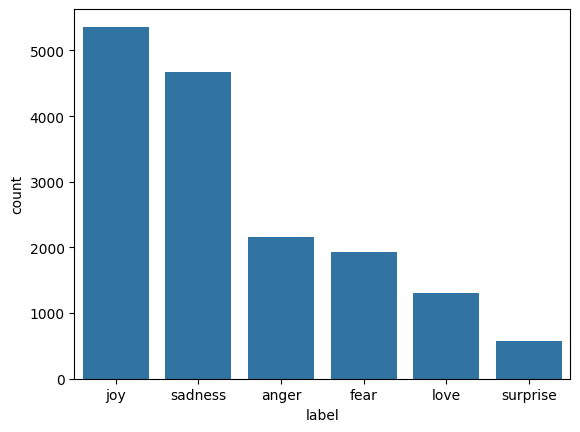

In [21]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

In [33]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configuration
max_words = 10000
max_len = 50

# Initialize tokenizer
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')

# Build vocabulary using training data only
tokenizer.fit_on_texts(df_train['text'])

# Convert text into numerical sequences
train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

# Apply padding and truncation
padded_train_sequence = pad_sequences(
    train_sequence, maxlen=max_len, padding='post', truncating='post'
)

padded_test_sequence = pad_sequences(
    test_sequence, maxlen=max_len, padding='post', truncating='post'
)

# Convert labels into NumPy arrays
train_labels = np.array(train_label)
test_labels = np.array(test_label)

# Calculate number of classes
num_classes = len(np.unique(train_labels))

# Display dataset information
print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Number of Classes: {num_classes}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")
print(f"Training Shape: {padded_train_sequence.shape}")
print(f"Testing Shape: {padded_test_sequence.shape}")


Vocabulary Size: 15213
Number of Classes: 6
Max Sentence Length: 50
Training Shape: (16000, 50)
Testing Shape: (2000, 50)


In [34]:
print(np.unique(train_labels, return_counts=True))

(array([0, 1, 2, 3, 4, 5]), array([4666, 5362, 1304, 2159, 1937,  572]))


In [35]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

class_weight_dict = dict(enumerate(class_weights))

print(class_weight_dict)

{0: np.float64(0.5715102157451064), 1: np.float64(0.49732686808404825), 2: np.float64(2.044989775051125), 3: np.float64(1.2351397251814111), 4: np.float64(1.3766993632765445), 5: np.float64(4.662004662004662)}


In [39]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

Models

In [36]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout , SimpleRNN , GRU

Model 1 — Simple RNN

In [37]:
rnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=128, input_length=max_len),
    SimpleRNN(units=64, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=32),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

rnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [40]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs=10,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.1681 - loss: 1.8632 - val_accuracy: 0.3200 - val_loss: 1.7693
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 55ms/step - accuracy: 0.1921 - loss: 1.7827 - val_accuracy: 0.0675 - val_loss: 1.8198
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 50ms/step - accuracy: 0.2163 - loss: 1.7245 - val_accuracy: 0.1475 - val_loss: 1.7984
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 25s 49ms/step - accuracy: 0.2628 - loss: 1.6157 - val_accuracy: 0.1850 - val_loss: 1.7671
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.3162 - loss: 1.4843 - val_accuracy: 0.2015 - val_loss: 1.8499
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 47ms/step - accuracy: 0.4077 - loss: 1.3141 - val_accuracy: 0.2405 - val_loss: 1.8657
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.4708 - loss: 1.1826 - val_accuracy: 0.2330 - val_loss: 1.9064


In [41]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.1850 - loss: 1.7671
RNN Loss: 1.767075538635254
RNN Accuracy: 0.1850000023841858


Model 2 — Standard LSTM

In [42]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [43]:
lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 88s 162ms/step - accuracy: 0.1428 - loss: 1.7951 - val_accuracy: 0.2710 - val_loss: 1.7594
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 148ms/step - accuracy: 0.1382 - loss: 1.7939 - val_accuracy: 0.1350 - val_loss: 1.7915
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 74s 149ms/step - accuracy: 0.1442 - loss: 1.7923 - val_accuracy: 0.2060 - val_loss: 1.7911
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 147ms/step - accuracy: 0.1659 - loss: 1.7870 - val_accuracy: 0.1740 - val_loss: 1.7962


In [44]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 56ms/step - accuracy: 0.2710 - loss: 1.7594
LSTM Loss: 1.7593982219696045
LSTM Accuracy: 0.2709999978542328


Model 3 — Standard GRU

In [45]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 100s 193ms/step - accuracy: 0.1566 - loss: 1.7959 - val_accuracy: 0.1140 - val_loss: 1.7872
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 83s 165ms/step - accuracy: 0.1649 - loss: 1.7942 - val_accuracy: 0.0360 - val_loss: 1.7923
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 77s 155ms/step - accuracy: 0.1604 - loss: 1.7943 - val_accuracy: 0.0810 - val_loss: 1.8063
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - accuracy: 0.1140 - loss: 1.7872
GRU Loss: 1.787165880203247
GRU Accuracy: 0.11400000005960464


In [46]:
result_df = pd.DataFrame({
    'Model': ['RNN',"LSTM","GRU"],
    "Test Loss ": [rnn_loss,lstm_loss,gru_loss],
    "Test Accuracy": [rnn_accuracy,lstm_accuracy,gru_accuracy]
})

Model 4 — Advanced Stacked Bidirectional GRU

In [47]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax') #Output Layer
    #Why i used num_classes in output layer and what will i get from this.
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [48]:
BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [49]:
BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [50]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 184s 353ms/step - accuracy: 0.5244 - loss: 1.1290 - val_accuracy: 0.8410 - val_loss: 0.4665
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 182s 364ms/step - accuracy: 0.8969 - loss: 0.2957 - val_accuracy: 0.9090 - val_loss: 0.2528
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 178s 355ms/step - accuracy: 0.9439 - loss: 0.1541 - val_accuracy: 0.9210 - val_loss: 0.2273
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 201s 354ms/step - accuracy: 0.9566 - loss: 0.1100 - val_accuracy: 0.9210 - val_loss: 0.2303
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 173s 346ms/step - accuracy: 0.9668 - loss: 0.0853 - val_accuracy: 0.9200 - val_loss: 0.2480
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 195s 390ms/step - accuracy: 0.9754 - loss: 0.0672 - val_accuracy: 0.9245 - val_loss: 0.2553


In [51]:

BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 8s 122ms/step - accuracy: 0.9210 - loss: 0.2273
BiGRU Loss: 0.22729109227657318
BiGRU Accuracy: 0.9210000038146973


Overall Evaluation

63/63 ━━━━━━━━━━━━━━━━━━━━ 12s 164ms/step


<Axes: >

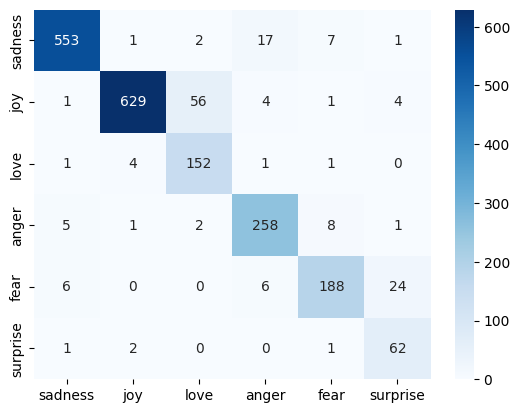

In [52]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence), axis=1)

sns.heatmap(confusion_matrix(test_label, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)


Final Predictions

In [53]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=max_len, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step


In [54]:
for i in range(len(sample_texts)):
  print(f"Text: {sample_texts[i]}\n Predicted Emotion: {label_names[sample_predictions[i]]}")

Text: I can't believe how happy I am right now, this is amazing!
 Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
 Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
 Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
 Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
 Predicted Emotion: surprise


Save Model & Tokenizer

In [55]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)

BiGRU.save(os.path.join(model_dir, 'BiGRU_Model.keras'))

with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)